# 16. Kiểm tra thang đo theo kênh

Bảng theo kênh của notebook 11 chứa bốn giá trị bất thường cần giải thích trước khi công bố: pH cho sai số bình phương 0,002093, MechVent cho 0,002544, WBC cho 0,014933 và Weight cho 0,084942. Dữ liệu đã được chuẩn hóa theo thống kê tập huấn luyện, nên sai số thường nằm quanh bậc đơn vị. Giá trị nhỏ hơn hai bậc so với kỳ vọng là dấu hiệu của một trong ba khả năng: độ lệch chuẩn tập huấn luyện bị giá trị ngoại lai thổi phồng, kênh có bản chất nhị phân nên phương sai thật rất nhỏ, hoặc kênh gần như không đổi trong cửa sổ bốn mươi tám giờ.

Câu hỏi cụ thể: với từng kênh, phân bố giá trị đã chuẩn hóa trên tập huấn luyện có đúng độ lệch chuẩn xấp xỉ một hay không, và nếu lệch thì lệch vì giá trị ngoại lai hay vì số mức giá trị rời rạc quá ít.

Thiết kế: đọc trực tiếp lưới đã tiền xử lý của lần chạy chốt, tính thống kê trên đúng các ô có phép đo thật, gồm trung bình, độ lệch chuẩn, phân vị một, năm mươi, chín mươi chín, giá trị nhỏ nhất, giá trị lớn nhất và số mức giá trị khác nhau. Sau đó đối chiếu với bảng theo kênh của notebook 11 và đánh cờ cho các kênh nghi vấn. Sổ tay này không huấn luyện mô hình nào và không cần bộ xử lý đồ họa. Chi phí dưới hai phút.

> **Vị trí trong chuỗi tái lập:** notebook 16 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 11-Chi_so_theo_nhom_kenh.
>
> **Thư mục kết quả:** `Output/processed/w3_23_kiem_tra_thang_do_kenh/`.
>
> **Mã định danh nội bộ:** `W3_23`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_23_kiem_tra_thang_do_kenh"  #@param {type:"string"}
NGUON_BANG_KENH = "w3_18_chi_so_theo_nhom_kenh"  #@param {type:"string"}
NGUONG_DO_LECH_THAP = 0.50  #@param {type:"number"}
NGUONG_SO_MUC_IT = 10  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_23_kiem_tra_thang_do_kenh
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:35:52
run_tag      w3_23_kiem_tra_thang_do_kenh
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Đọc lưới đã tiền xử lý

Sổ tay này không dùng hàm nạp lát của các sổ tay huấn luyện, vì ở đây cần toàn bộ bốn mươi tám giờ chứ không chỉ cửa sổ đầu vào. Thống kê được tính riêng cho tập huấn luyện, vì đó mới là tập đã sinh ra tham số chuẩn hóa.

In [4]:
d_train = np.load(PROC / "train.npz")
X_TRAIN = d_train["X"].astype(np.float64)
M_TRAIN = d_train["M"].astype(np.float64)
N_CH = X_TRAIN.shape[-1]
print("Lưới huấn luyện:", X_TRAIN.shape[0], "hồ sơ |", X_TRAIN.shape[1], "giờ |",
      N_CH, "kênh")
print("Tỷ lệ ô có phép đo thật:", round(100.0 * float(M_TRAIN.mean()), 2), "phần trăm")
print("Phạm vi chuẩn hóa của lần chạy nguồn:", meta["norm_scope"],
      "| ngưỡng cắt sigma:", meta["clip_sigma"])


Lưới huấn luyện: 5600 hồ sơ | 48 giờ | 37 kênh
Tỷ lệ ô có phép đo thật: 20.16 phần trăm
Phạm vi chuẩn hóa của lần chạy nguồn: train_only | ngưỡng cắt sigma: 0.0


## 3. Thống kê phân bố đã chuẩn hóa theo từng kênh

Chỉ các ô có phép đo thật tham gia thống kê. Lấy cả ô trống sẽ kéo mọi thống kê về không và che mất đúng điều cần kiểm tra. Số mức giá trị khác nhau được đếm để phân biệt kênh liên tục với kênh thực chất là nhị phân hoặc rời rạc thô.

In [5]:
THONG_KE_KENH = []
for i in range(N_CH):
    gia_tri = X_TRAIN[:, :, i][M_TRAIN[:, :, i] > 0]
    if gia_tri.size == 0:
        THONG_KE_KENH.append({"kenh": str(channels[i]), "so_diem": 0})
        continue
    THONG_KE_KENH.append({
        "kenh": str(channels[i]),
        "so_diem": int(gia_tri.size),
        "do_phu_huan_luyen": float(M_TRAIN[:, :, i].mean()),
        "trung_binh": float(gia_tri.mean()),
        "do_lech_chuan": float(gia_tri.std(ddof=1)) if gia_tri.size > 1 else 0.0,
        "nho_nhat": float(gia_tri.min()),
        "phan_vi_1": float(np.percentile(gia_tri, 1)),
        "phan_vi_50": float(np.percentile(gia_tri, 50)),
        "phan_vi_99": float(np.percentile(gia_tri, 99)),
        "lon_nhat": float(gia_tri.max()),
        "so_muc_gia_tri": int(np.unique(gia_tri).size),
        "mu_goc": float(meta["mu"][i]),
        "sd_goc": float(meta["sd"][i]),
    })

for r in THONG_KE_KENH:
    if r["so_diem"] == 0:
        print(r["kenh"].ljust(14), "không có phép đo thật nào trên tập huấn luyện")
        continue
    print(r["kenh"].ljust(14), "độ lệch chuẩn", str(round(r["do_lech_chuan"], 4)).ljust(8),
          "| phân vị 1 và 99", round(r["phan_vi_1"], 3), round(r["phan_vi_99"], 3),
          "| lớn nhất", round(r["lon_nhat"], 2),
          "| số mức", r["so_muc_gia_tri"])


Albumin        độ lệch chuẩn 1.0001   | phân vị 1 và 99 -2.184 2.172 | lớn nhất 3.73 | số mức 43
ALP            độ lệch chuẩn 1.0001   | phân vị 1 và 99 -0.675 4.573 | lớn nhất 15.98 | số mức 457
ALT            độ lệch chuẩn 1.0001   | phân vị 1 và 99 -0.311 5.081 | lớn nhất 14.73 | số mức 923
AST            độ lệch chuẩn 1.0001   | phân vị 1 và 99 -0.321 5.269 | lớn nhất 12.85 | số mức 1004
Bilirubin      độ lệch chuẩn 1.0001   | phân vị 1 và 99 -0.47 4.911 | lớn nhất 8.72 | số mức 281
BUN            độ lệch chuẩn 1.0      | phân vị 1 và 99 -1.031 3.81 | lớn nhất 8.07 | số mức 196
Cholesterol    độ lệch chuẩn 1.001    | phân vị 1 và 99 -1.965 2.801 | lớn nhất 4.12 | số mức 165
Creatinine     độ lệch chuẩn 1.0      | phân vị 1 và 99 -0.759 4.522 | lớn nhất 13.45 | số mức 165
DiasABP        độ lệch chuẩn 1.0      | phân vị 1 và 99 -1.926 2.752 | lớn nhất 16.39 | số mức 1147
FiO2           độ lệch chuẩn 1.0      | phân vị 1 và 99 -1.281 2.402 | lớn nhất 2.4 | số mức 83
GCS            độ 

## 4. Đánh cờ các kênh nghi vấn

Ba cờ được đặt theo ba cả chỉ tiêu khách quan, không phụ thuộc vào kết quả mô hình. Cờ thứ nhất cho kênh có độ lệch chuẩn đã chuẩn hóa thấp bất thường. Cờ thứ hai cho kênh có quá ít mức giá trị. Cờ thứ ba cho kênh có đuôi dài, nhận biết qua tỷ số giữa biên độ toàn phần và biên độ giữa hai phân vị một và chín mươi chín.

In [6]:
for r in THONG_KE_KENH:
    if r["so_diem"] == 0:
        r["co_nghi_van"] = True
        r["ly_do"] = ["không có phép đo thật"]
        continue
    bien_do_phan_vi = r["phan_vi_99"] - r["phan_vi_1"]
    bien_do_toan_phan = r["lon_nhat"] - r["nho_nhat"]
    r["ty_so_duoi"] = float(bien_do_toan_phan / max(bien_do_phan_vi, 1e-9))
    ly_do = []
    if r["do_lech_chuan"] < NGUONG_DO_LECH_THAP:
        ly_do.append("độ lệch chuẩn thấp bất thường")
    if r["so_muc_gia_tri"] <= NGUONG_SO_MUC_IT:
        ly_do.append("quá ít mức giá trị")
    if r["ty_so_duoi"] > 10.0:
        ly_do.append("đuôi phân bố rất dài")
    r["ly_do"] = ly_do
    r["co_nghi_van"] = len(ly_do) > 0

NGHI_VAN = [r for r in THONG_KE_KENH if r["co_nghi_van"]]
print("Số kênh bị đánh cờ:", len(NGHI_VAN), "trên", N_CH)
for r in NGHI_VAN:
    print("   ", r["kenh"].ljust(14), "|", "; ".join(r["ly_do"]))


Số kênh bị đánh cờ: 5 trên 37
    MechVent       | độ lệch chuẩn thấp bất thường; quá ít mức giá trị
    pH             | đuôi phân bố rất dài
    TropI          | không có phép đo thật
    TropT          | không có phép đo thật
    WBC            | đuôi phân bố rất dài


## 5. Đối chiếu với bảng theo kênh của notebook 11

Bước này trả lời trực tiếp câu hỏi đã nêu trong bản rà soát: bốn kênh có sai số bất thường nhỏ có nằm trong danh sách bị đánh cờ hay không. Nếu có, bất thường đó thuộc về thang đo chứ không phải lỗi của mô hình, và báo cáo chỉ cần một ghi chú rõ ràng thay vì một lần chạy lại.

In [7]:
tep_18 = OUT / "processed" / NGUON_BANG_KENH / "W3_chi_so_theo_nhom_kenh.json"
GHEP = []
if tep_18.exists():
    d18 = {r["kenh"]: r for r in json.loads(tep_18.read_text())["bang_kenh"]}
    for r in THONG_KE_KENH:
        g = dict(r)
        cu = d18.get(r["kenh"], {})
        g["mse_neoA_w3_18"] = cu.get("mse_neoA")
        g["mse_neoB_w3_18"] = cu.get("mse_neoB")
        g["hieu_ung_mse_w3_18"] = cu.get("hieu_ung_mse")
        g["nhom_w3_18"] = cu.get("nhom")
        GHEP.append(g)
    co_so = [g for g in GHEP if g.get("mse_neoA_w3_18") is not None]
    thap = sorted(co_so, key=lambda g: g["mse_neoA_w3_18"])[:6]
    print("Sáu kênh có sai số bình phương nhỏ nhất trong notebook 11:")
    for g in thap:
        print("   ", g["kenh"].ljust(14), "MSE neo A", round(g["mse_neoA_w3_18"], 6),
              "| độ lệch chuẩn", round(g.get("do_lech_chuan", 0.0), 4),
              "| số mức", g.get("so_muc_gia_tri"),
              "| cờ", "; ".join(g["ly_do"]) or "không")
    tq = float(np.corrcoef([g["do_lech_chuan"] for g in co_so],
                           [g["mse_neoA_w3_18"] for g in co_so])[0, 1])
    print("Tương quan giữa độ lệch chuẩn đã chuẩn hóa và sai số neo A:", round(tq, 5))
else:
    tq = None
    print("Không thấy tệp kết quả của notebook 11, bỏ qua bước đối chiếu")


Sáu kênh có sai số bình phương nhỏ nhất trong notebook 11:
    pH             MSE neo A 0.002093 | độ lệch chuẩn 1.0 | số mức 163 | cờ đuôi phân bố rất dài
    MechVent       MSE neo A 0.002544 | độ lệch chuẩn 0.0 | số mức 1 | cờ độ lệch chuẩn thấp bất thường; quá ít mức giá trị
    WBC            MSE neo A 0.014933 | độ lệch chuẩn 1.0 | số mức 591 | cờ đuôi phân bố rất dài
    Weight         MSE neo A 0.084942 | độ lệch chuẩn 1.0 | số mức 1155 | cờ không
    HR             MSE neo A 0.370972 | độ lệch chuẩn 1.0 | số mức 1732 | cờ không
    ALT            MSE neo A 0.388116 | độ lệch chuẩn 1.0001 | số mức 923 | cờ không
Tương quan giữa độ lệch chuẩn đã chuẩn hóa và sai số neo A: 0.33811


## 6. Hai hình chẩn đoán

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_23_kiem_tra_thang_do_kenh/figures/W3_23_kiem_tra_thang_do_kenh.png


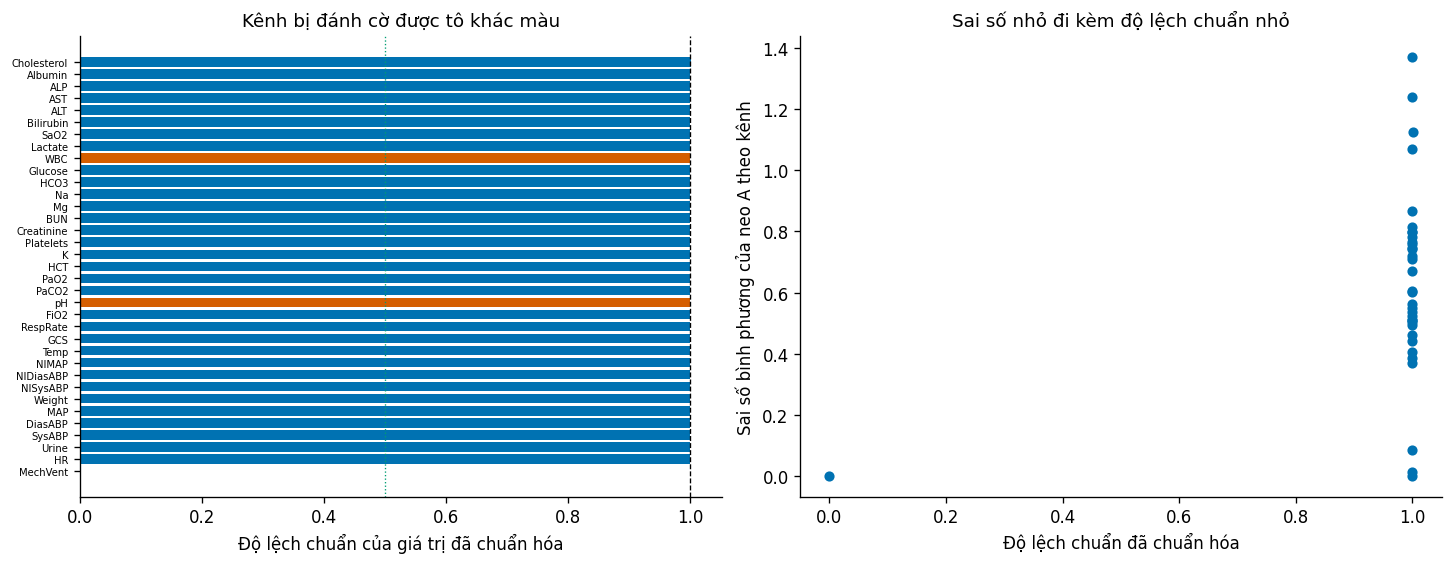

In [8]:
co_diem = [r for r in THONG_KE_KENH if r["so_diem"] > 0]
sd = [r["do_lech_chuan"] for r in co_diem]
ten_kenh = [r["kenh"] for r in co_diem]
thu_tu = np.argsort(sd)

fig, ax = plt.subplots(1, 2, figsize=(12.0, 4.6))
mau = [PALETTE[1] if co_diem[i]["co_nghi_van"] else PALETTE[0] for i in thu_tu]
ax[0].barh(np.arange(len(thu_tu)), [sd[i] for i in thu_tu], color=mau)
ax[0].axvline(1.0, color="black", linewidth=0.8, linestyle="--")
ax[0].axvline(NGUONG_DO_LECH_THAP, color=PALETTE[2], linewidth=0.8, linestyle=":")
ax[0].set_yticks(np.arange(len(thu_tu)))
ax[0].set_yticklabels([ten_kenh[i] for i in thu_tu], fontsize=6)
ax[0].set_xlabel("Độ lệch chuẩn của giá trị đã chuẩn hóa")
ax[0].set_title("Kênh bị đánh cờ được tô khác màu")

if GHEP:
    x = [g["do_lech_chuan"] for g in GHEP if g.get("mse_neoA_w3_18") is not None]
    y = [g["mse_neoA_w3_18"] for g in GHEP if g.get("mse_neoA_w3_18") is not None]
    ax[1].scatter(x, y, s=26, color=PALETTE[0])
    ax[1].set_xlabel("Độ lệch chuẩn đã chuẩn hóa")
    ax[1].set_ylabel("Sai số bình phương của neo A theo kênh")
    ax[1].set_title("Sai số nhỏ đi kèm độ lệch chuẩn nhỏ")
else:
    ax[1].axis("off")
luu_hinh(fig, "W3_23_kiem_tra_thang_do_kenh.png")
plt.show()


## 7. Ghi kết quả

In [9]:
ket_qua = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG,
    "nguong_do_lech_thap": NGUONG_DO_LECH_THAP,
    "nguong_so_muc_it": NGUONG_SO_MUC_IT,
    "pham_vi_chuan_hoa": meta["norm_scope"], "clip_sigma": meta["clip_sigma"],
    "so_kenh": int(N_CH),
    "so_kenh_nghi_van": len(NGHI_VAN),
    "danh_sach_nghi_van": [r["kenh"] for r in NGHI_VAN],
    "tuong_quan_do_lech_va_mse_neoA": tq,
    "bang_thang_do": GHEP or THONG_KE_KENH,
}
dich = RUN_DIR / "W3_kiem_tra_thang_do_kenh.json"
dich.write_text(json.dumps(ket_qua, ensure_ascii=False, indent=2))
print("Đã ghi", dich)


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_23_kiem_tra_thang_do_kenh/W3_kiem_tra_thang_do_kenh.json
